In [1]:
#Definicion de librerias

import qutip as qt
import numpy as np
import random

%matplotlib inline
from IPython.display import Image
from qutip import *
from qutip_qip.operations import *
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator


In [2]:
#Definición de los dos estados de la base 
psi_0=qt.basis(2,0)
psi_1=qt.basis(2,1)


#Definicion del estado inicial como superposicion de los estados de la base
#coeficientes
a=1
b=1

psi_superposition=(a*psi_0+b*psi_1).unit()

psi_superposition

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.70710678]]

In [3]:
#Definicion de matrices de pauli

sigma_x=qt.sigmax()
sigma_y=qt.sigmay()
sigma_z=qt.sigmaz()

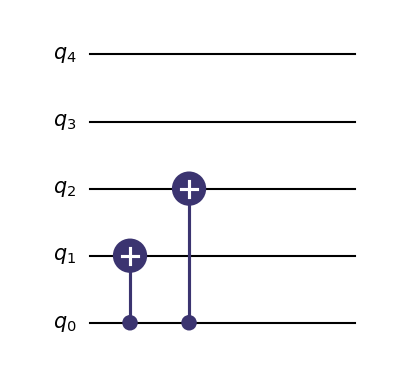

In [4]:
#ejercicio 7
#creamos un circuito de codificación de 3 qubits
q0=psi_superposition  # Estado |ψ>
q1=qt.basis(2, 0)  # Estado |0>
q2=qt.basis(2, 0)  # Estado |0>
q_total = tensor(q0, q1, q2, q1, q1)
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc

In [5]:
U7=gate_sequence_product(qenc.propagators())
q_encoded7 = U7*q_total

In [6]:
#ejercicio7
#introducimos un error de bit-flip en uno de los qubits
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()

errorstate = tensor(error_op) * q_encoded7
errorstate = errorstate.unit()
errorstate

Bit-flipping qubit 2


Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [7]:
#ejercicio 7
#definimos los operadores de control para la corrección de errores
op_Z1 = tensor(sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
op_Z2 = tensor(qt.qeye(2), sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2))


#aplicamos los operadores de control al estado con error y calculamos los valores esperados

val_ZZI = round(expect(op_Z1, errorstate))
val_IZZ = round(expect(op_Z2, errorstate))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("No error detected.")
elif val_ZZI == -1 and val_IZZ == 1:
    print("Error detected on qubit 0.")
elif val_ZZI == 1 and val_IZZ == -1:
    print("Error detected on qubit 2.")
elif val_ZZI == -1 and val_IZZ == -1:
    print("Error detected on qubit 1.")


 <Z Z I>: 1
 <I Z Z>: -1
Error detected on qubit 2.


Bit-flipping qubit 0


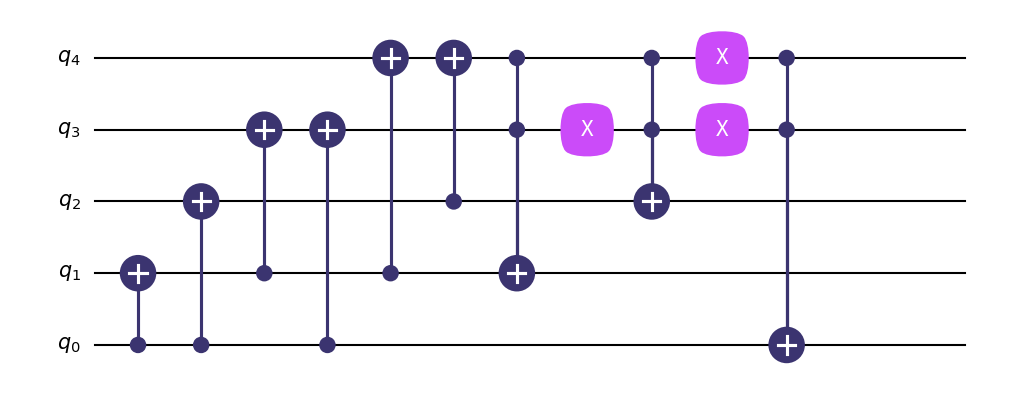

In [8]:
#ejercicio 8
#circuito
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()
qenc.add_gate("CNOT", controls=[1], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[1], targets=[4])
qenc.add_gate("CNOT", controls=[2], targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[1])
qenc.add_gate("X", targets=[3])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[2])
qenc.add_gate("X", targets=[3])
qenc.add_gate("X", targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[0])
qenc

In [9]:
#ejercicio 8
#implementación del circuito de corrección de errores sobre chi 
U8=gate_sequence_product(qenc.propagators())
q_encoded8=U8*q_total

#comprobación de si se ha corregido el error
val_ZZI = round(expect(op_Z1, q_encoded8))
val_IZZ = round(expect(op_Z2, q_encoded8))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("se ha corregido el error.")
else:
    print("no se ha corregido el error.")

 <Z Z I>: 1
 <I Z Z>: 1
se ha corregido el error.
